# Does excluding low-extent GFTM modes fix KBM mode selection?

Fusion_PhD-38e9.1. On the KBM Latin hypercubes most GFTM error is mode **selection**, not
identification: a mode close to GS2 is in GFTM's 4-mode spectrum but is not the fastest one.
Hypothesis: spurious fast modes with a short ballooning-angle **extent** win the argmax.

Data: the WIDTH-oracle scan (`wo_*` leaves; `docs/gyro_data_runs.md` in Fusion_PhD), GFTM at fixed
NBASIS_MAX=22 / NXGRID=28, FILTER=0.0, NMODES=4, 24 fixed widths 0.2-4.0, on SPR-045 (`KB_MODELS`)
and M1 (`KB_MODELS_MAST`). GS2 reference: the tail-averaged `pyro_cube_avg` bundles.
Extent: `pyrokinetics.diagnostics.extent.Extent` (branch `feature/extent_diagnostic`, 95% rule),
applied to each cube's `eigenfunctions`.

Sections: (a) the premise measured, (b) extent of spurious vs oracle modes, (c) the cutoff sweep,
plus three checks on the extent numbers. (d), the tearing-parity baseline, is DEFERRED to pyro#594:
FieldLine.compute_linear_tearing_parameter cannot read these GFTM cubes, and parity is not reimplemented here.

**The oracle (mode closest to GS2) consults the answer: it is a bound, never an accuracy.**

## Imports and settings

In [1]:
from pathlib import Path
import os
import warnings
from dotenv import load_dotenv
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import pyrokinetics
from pyrokinetics import Pyro
from pyrokinetics.pyroscan import PyroScanGKOutput
from pyrokinetics.dataset_wrapper import DatasetWrapper
from pyrokinetics.diagnostics.extent import Extent
from pyrokinetics.diagnostics.field_line import FieldLine

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir()
)
plt.style.use(ROOT / "src/general_analysis/paper.mplstyle")
load_dotenv(ROOT / "local.env", override=True)
print("pyrokinetics", pyrokinetics.__version__)

analysis_name = "kbm_extent_filter"
data_root = Path(os.environ["GK_DATA_ROOT"]).expanduser()
run_template = "Runs"
project = "LATIN_HYPERCUBE"
cases = {"SPR-045": "SPR-045", "M1": "M1"}  # database label -> case directory
scan_information = {"GFTM": "kbm_8d/wo_{width}", "GS2": "kbm_8d"}
output_dir = {"GFTM": "pyro_cube", "GS2": "pyro_cube_avg"}  # GS2: tail-averaged reference
output_file = "cube.nc"
gs2_input_file = "gs2.in"   # per-run GS2 input (scan dir / sample name / this); pyro reads gs2.out.nc beside it
widths = ["w0p2000", "w0p2297", "w0p2639", "w0p3031", "w0p3482", "w0p4000", "w0p4595",
          "w0p5279", "w0p6063", "w0p6965", "w0p8000", "w0p9000", "w1p0000", "w1p1000",
          "w1p2000", "w1p3000", "w1p4000", "w1p5000", "w1p6000", "w1p9218", "w2p3083",
          "w2p7726", "w3p3302", "w4p0000"]
width_value = {w: float(w[1:].replace("p", ".")) for w in widths}
expected_resolution = {"nbasis_used": 22, "nxgrid_used": 28}

fraction = 0.95                             # Extent's rule: theta range holding 95% of |Re field|^2
fields = ["phi", "apar"]                    # phi selects; apar reported alongside
cutoffs = np.round(np.arange(0, 12.01, 0.25), 2)       # absolute extent cutoff [rad]
rel_cutoffs = np.round(np.arange(0, 1.001, 0.05), 2)   # fraction of the case's largest unstable-mode extent
edge_amplitude = 0.05    # check 1: |phi| at the theta-grid edge above this fraction of its peak
delta_lim = 0.2          # fig 2 colour range for the medlog change (clipped; misses-dominate cells are grey)
example_width = "w1p0000"
n_examples = 3

pyrokinetics 0.9.2.dev30+gfa3864e7


## Load data

One `PyroScanGKOutput` per (database, width), read from the cube's netCDF. The extent branch has no
`PyroHypercube` or GFTM reader, so the cube is loaded as the scan's gk_output object, which carries
units. `Extent` adds `extent(sample, field, mode)` and `bounds(..., bound=lo/hi)` in place.

In [2]:
gs2, gftm = {}, {}
for db, case in cases.items():
    gs2[db] = PyroScanGKOutput.from_netcdf(
        data_root / "GS2" / run_template / project / case / scan_information["GS2"] / output_dir["GS2"] / output_file)
    Extent(gs2[db], fraction=fraction)   # GS2 extents: used by the GFTM-vs-GS2 extent comparison at the end
    for w in widths:
        out = PyroScanGKOutput.from_netcdf(
            data_root / "GFTM" / run_template / project / case / scan_information["GFTM"].format(width=w)
            / output_dir["GFTM"] / output_file)
        Extent(out, fraction=fraction)
        gftm[db, w] = out
    print(db, "GS2 samples", gs2[db].data.sizes["sample"], "| GFTM cubes", len(widths))

SPR-045 GS2 samples 300 | GFTM cubes 24
M1 GS2 samples 300 | GFTM cubes 24


## Calculate and select

Conventions, checked rather than assumed: both codes' growth rates are in the same pyrokinetics
units; each cube's audited resolution (`*_used`, from `out.gftm.localdump`) is the requested one.

Per case, GFTM returns 4 modes. A **selector** takes the argmax growth rate over `mode` among
*unstable* modes (gamma > 0) that pass its gate. A case where no unstable mode passes is a **MISS**:
it stays in the population with gamma_sel = 0, so its |log10| error is +inf and its absolute error is
gamma_GS2. Misses therefore move the median, and medlog becomes inf once they are the majority.

Population: cases whose GS2 growth rate is finite and positive (the same cases for every selector
and width, so every comparison is paired).

- `dominant`: no gate (c = 0; the current argmax over unstable modes).
- `oracle`: the unstable mode with the smallest |log10(gamma/gamma_GS2)| -- a bound.
- `extent >= c`: absolute cutoff on the 95% extent of phi (apar alongside).
- `extent >= r * max extent`: relative cutoff on the case's own longest unstable mode.

In [3]:
def mag(v):
    return np.asarray(getattr(v.data, "magnitude", v.data))


def select(gam, keep):
    # argmax growth over 'mode' among unstable modes passing `keep`; 0 where none passes (a MISS)
    g = np.where(keep & (gam > 0), gam, -np.inf)
    idx = g.argmax(axis=1)
    return np.where(np.isfinite(g.max(axis=1)), gam[np.arange(len(gam)), idx], 0.0), idx


def score(g_sel, g_ref):
    with np.errstate(divide="ignore"):
        log_err = np.abs(np.log10(g_sel / g_ref))
    return np.median(np.abs(g_sel - g_ref)), np.median(log_err), int((g_sel == 0).sum())


rows, sweep, cases_data = [], [], {}
for (db, w), out in gftm.items():
    d, ref = out.data, gs2[db].data
    assert str(d.growth_rate.data.units) == str(ref.growth_rate.data.units), "normalisations differ"
    for var, value in expected_resolution.items():
        assert (mag(d[var]) == value).all(), f"{db}/{w}: {var} is not {value}"
    assert np.allclose(mag(d.width_used), width_value[w])

    ref_by_name = dict(zip(ref.sample_name.values, mag(ref.growth_rate)))
    g_ref_all = np.array([ref_by_name.get(n, np.nan) for n in d.sample_name.values])
    ok = np.isfinite(g_ref_all) & (g_ref_all > 0)
    g_ref = g_ref_all[ok]
    gam = mag(d.growth_rate.transpose("sample", "mode"))[ok]
    ext = {f: mag(d.extent.sel(field=f).transpose("sample", "mode"))[ok] for f in fields}
    theta = d.theta.values
    phi = mag(d.eigenfunctions.sel(field="phi").transpose("sample", "theta", "mode"))[ok]

    unstable = gam > 0
    g_dom, i_dom = select(gam, True)
    with np.errstate(divide="ignore", invalid="ignore"):
        dist = np.where(unstable, np.abs(np.log10(gam / g_ref[:, None])), np.inf)
    i_orc = dist.argmin(axis=1)
    g_orc = np.where(unstable.any(axis=1), gam[np.arange(len(gam)), i_orc], 0.0)

    # check 1: 95% bounds within one grid spacing of the edge, or |phi| at the edge above edge_amplitude of peak
    lo, hi = (mag(d.bounds.sel(field="phi", bound=b).transpose("sample", "mode"))[ok] for b in ("lo", "hi"))
    dtheta = theta[1] - theta[0]
    at_edge = (lo <= theta[0] + dtheta) | (hi >= theta[-1] - dtheta)
    edge_amp = np.maximum(np.abs(phi[:, 0]), np.abs(phi[:, -1])) / np.abs(phi).max(axis=1)

    # check 2: rotate each eigenfunction so its peak is real, recompute Extent
    e = mag(d.eigenfunctions)
    axis = d.eigenfunctions.get_axis_num("theta")
    peak = np.take_along_axis(e, np.abs(e).argmax(axis=axis, keepdims=True), axis=axis)
    rot = DatasetWrapper(data_vars={"eigenfunctions": d.eigenfunctions.copy(data=e * np.exp(-1j * np.angle(peak)))})
    Extent(rot, fraction=fraction)
    with np.errstate(divide="ignore", invalid="ignore"):
        phase_change = {f: np.abs(mag(rot.data.extent.sel(field=f).transpose("sample", "mode"))[ok] - ext[f]) / ext[f]
                        for f in fields}
    del rot

    differ = i_dom != i_orc
    with np.errstate(divide="ignore"):
        err_dom, err_orc = np.abs(np.log10(g_dom / g_ref)), np.abs(np.log10(g_orc / g_ref))
    r = np.arange(len(gam))
    row = dict(db=db, width=width_value[w], n=int(ok.sum()), n_gs2_stable_or_nan=int((~ok).sum()),
               differ=int(differ.sum()),
               medlog_dom=score(g_dom, g_ref)[1], medlog_orc=score(g_orc, g_ref)[1],
               medAE_dom=score(g_dom, g_ref)[0], medAE_orc=score(g_orc, g_ref)[0],
               medlog_dom_agree=np.median(err_dom[~differ]), medlog_dom_differ=np.median(err_dom[differ]),
               medlog_orc_differ=np.median(err_orc[differ]),
               share_err_from_differ=err_dom[differ & np.isfinite(err_dom)].sum() / err_dom[np.isfinite(err_dom)].sum(),
               unstable_modes=int(unstable.sum()), unstable_nan_extent=int((unstable & ~np.isfinite(ext["phi"])).sum()),
               frac_bounds_at_edge=at_edge[unstable].mean(), frac_edge_amp=(edge_amp[unstable] > edge_amplitude).mean(),
               **{f"phase_{f}_median_rel_change": np.nanmedian(phase_change[f][unstable]) for f in fields},
               **{f"phase_{f}_frac_over_10pct": (phase_change[f][unstable] > 0.1).mean() for f in fields})
    for f in fields:
        a, b = ext[f][r, i_dom][differ], ext[f][r, i_orc][differ]
        row[f"{f}_ext_dom_shorter"] = (a < b).mean()
        row[f"{f}_ext_ratio_median"] = np.median(a / b)
    rows.append(row)

    longest = np.nanmax(np.where(unstable, ext["phi"], np.nan), axis=1, initial=0)
    for f in fields:
        for kind, grid in (("abs", cutoffs), ("rel", rel_cutoffs)):
            for c in grid:
                threshold = c if kind == "abs" else c * longest[:, None]
                keep = (ext[f] >= threshold) | (c == 0)   # c = 0 keeps NaN-extent modes: exactly `dominant`
                medAE, medlog, miss = score(select(gam, keep)[0], g_ref)
                sweep.append(dict(db=db, width=width_value[w], field=f, kind=kind, cutoff=c,
                                  medlog=medlog, medAE=medAE, miss=miss, n=len(g_ref)))
    cases_data[db, w] = dict(names=d.sample_name.values[ok], gam=gam, g_ref=g_ref, i_dom=i_dom, i_orc=i_orc,
                             ext=ext, err_dom=err_dom, differ=differ)

summary = pd.DataFrame(rows)
sweep = pd.DataFrame(sweep)

## Interpretation

See the Fusion_PhD `results/kbm_extent_filter/README.md` for the verdict written from this notebook's
executed output. Limitations: the oracle consults GS2 and is a bound; extents come from pyro's fixed
output theta grid (+-9 pi), so edge-limited modes (check 1) give lower bounds; |Re(phi)| makes extent
phase-dependent (check 2), and the apar extent strongly so; the tearing-parity baseline is deferred
to pyro#594.

# Does GFTM's own parity filter (FILTER=0.5) fix KBM mode selection?

Fusion_PhD-38e9.2. The extent cutoff above did not separate spurious modes. GFTM has its own solver-side
parity gate: `FILTER` (gftm_LS.f90:582 flags TM_PARITY when phi_norm_even < FILTER, :325 discards it).
qp5.20 found FILTER=0.5 cut gftm_fw04's medAE on SPR-045 0.048 -> 0.013, at one width. Here the whole width axis.

Data: the `wo_f05_*` leaves, identical to `wo_*` (NBASIS_MAX 22, NXGRID 28, NMODES 4, FIND_WIDTH F, 24 widths)
with **FILTER=0.5 the only difference** (`wo_*` run FILTER=0.0). The parity filter is GFTM's own, not reimplemented here.

Scoring, per (database, width), **paired on the same GS2-unstable cases** as the sections above: the dominant
mode (argmax growth rate over `mode` among unstable modes) for FILTER=0.0 and FILTER=0.5, medlog and medAE.
A case with no unstable mode returned is a **MISS**: kept in the population as +inf log error (and |gamma_GS2| absolute
error), counted. The FILTER=0.0 oracle (mode closest to GS2) is a **bound, never an accuracy**.

## FILTER=0.5: settings and data

In [13]:
scan_information_f05 = "kbm_8d/wo_f05_{width}"
filter_requested = 0.5

gftm05 = {}
for db, case in cases.items():
    for w in widths:
        out = PyroScanGKOutput.from_netcdf(
            data_root / "GFTM" / run_template / project / case / scan_information_f05.format(width=w)
            / "pyro_cube" / output_file)
        Extent(out, fraction=fraction)   # used by the extent-on-top-of-FILTER=0.5 section at the end
        gftm05[db, w] = out
print("FILTER=0.5 cubes loaded:", len(gftm05))

FILTER=0.5 cubes loaded: 48


## FILTER=0.5: calculate

Checked, not assumed: FILTER *used* (from `out.gftm.localdump`) is 0.5 in every sample and 0.0 in the `wo_*` arm;
resolution and WIDTH are the requested ones; samples are the same and in the same order in both arms.

In [14]:
rows05 = []
for (db, w), out in gftm05.items():
    d0, d5, ref = gftm[db, w].data, out.data, gs2[db].data
    assert (d0.sample_name.values == d5.sample_name.values).all(), "arms are not sample-aligned"
    assert (mag(d5.filter_used) == filter_requested).all() and (mag(d5.filter_requested) == filter_requested).all()
    for var, value in expected_resolution.items():
        assert (mag(d5[var]) == value).all(), f"{db}/{w}: {var} is not {value}"
    assert np.allclose(mag(d5.width_used), width_value[w])

    ref_by_name = dict(zip(ref.sample_name.values, mag(ref.growth_rate)))
    freq_ref_by_name = dict(zip(ref.sample_name.values, mag(ref.mode_frequency)))
    g_ref_all = np.array([ref_by_name.get(n, np.nan) for n in d5.sample_name.values])
    freq_ref_all = np.array([freq_ref_by_name.get(n, np.nan) for n in d5.sample_name.values])
    ok = np.isfinite(g_ref_all) & (g_ref_all > 0)
    g_ref = g_ref_all[ok]
    freq_ref = freq_ref_all[ok]
    assert np.isfinite(freq_ref).all(), f"{db}/{w}: GS2 reference frequency is non-finite"
    gam0 = mag(d0.growth_rate.transpose("sample", "mode"))[ok]
    gam5 = mag(d5.growth_rate.transpose("sample", "mode"))[ok]
    freq0 = mag(d0.mode_frequency.transpose("sample", "mode"))[ok]
    freq5 = mag(d5.mode_frequency.transpose("sample", "mode"))[ok]
    assert np.isfinite(freq0[gam0 > 0]).all(), f"{db}/{w}: unstable FILTER=0.0 frequency is non-finite"
    assert np.isfinite(freq5[gam5 > 0]).all(), f"{db}/{w}: unstable FILTER=0.5 frequency is non-finite"
    assert str(d0.mode_frequency.data.units) == str(d5.mode_frequency.data.units) == str(ref.mode_frequency.data.units), "frequency normalisations differ"

    g_dom0, i_dom0 = select(gam0, True)
    g_dom5, i_dom5 = select(gam5, True)
    with np.errstate(divide="ignore", invalid="ignore"):
        dist = np.where(gam0 > 0, np.abs(np.log10(gam0 / g_ref[:, None])), np.inf)
    i_orc = dist.argmin(axis=1)
    g_orc = np.where((gam0 > 0).any(axis=1), gam0[np.arange(len(gam0)), i_orc], 0.0)

    sample_idx = np.arange(len(gam0))
    freq_dom0 = np.where((gam0 > 0).any(axis=1), freq0[sample_idx, i_dom0], 0.0)
    freq_dom5 = np.where((gam5 > 0).any(axis=1), freq5[sample_idx, i_dom5], 0.0)
    freq_dist = np.where((gam0 > 0) & np.isfinite(freq0), np.abs(freq0 - freq_ref[:, None]), np.inf)
    i_freq_orc = freq_dist.argmin(axis=1)
    has_freq_oracle = np.isfinite(freq_dist).any(axis=1)
    freq_orc = np.where(has_freq_oracle, freq0[sample_idx, i_freq_orc], 0.0)
    g_orcw = np.where(has_freq_oracle, gam0[sample_idx, i_freq_orc], 0.0)            # growth rate of the frequency oracle
    freq_orcg = np.where((gam0 > 0).any(axis=1), freq0[sample_idx, i_orc], 0.0)       # frequency of the growth oracle

    ae0, ml0, miss0 = score(g_dom0, g_ref)
    ae5, ml5, miss5 = score(g_dom5, g_ref)
    aeo, mlo, misso = score(g_orc, g_ref)
    aeow, mlow, missow = score(g_orcw, g_ref)
    rows05.append(dict(db=db, width=width_value[w], n=int(ok.sum()), medlog_f00=ml0, medlog_f05=ml5, medlog_orc=mlo,
                       medAE_f00=ae0, medAE_f05=ae5, medAE_orc=aeo, miss_f00=miss0, miss_f05=miss5, miss_orc=misso,
                       medlog_orcw=mlow, medAE_orcw=aeow, miss_orcw=missow,
                       medAE_freq_f00=np.median(np.abs(freq_dom0 - freq_ref)),
                       medAE_freq_f05=np.median(np.abs(freq_dom5 - freq_ref)),
                       medAE_freq_orc=np.median(np.abs(freq_orc - freq_ref)),
                       medAE_freq_orcg=np.median(np.abs(freq_orcg - freq_ref)),
                       miss_freq_f00=int((~(gam0 > 0).any(axis=1)).sum()),
                       miss_freq_f05=int((~(gam5 > 0).any(axis=1)).sum()),
                       miss_freq_orc=int((~has_freq_oracle).sum()),
                       same_mode=int((gam0[sample_idx, i_dom0] == gam5[sample_idx, i_dom5]).sum())))
f05 = pd.DataFrame(rows05).sort_values(["db", "width"]).reset_index(drop=True)
f05["gap_closed_medlog"] = (f05.medlog_f00 - f05.medlog_f05) / (f05.medlog_f00 - f05.medlog_orc)
f05["d_medlog"] = f05.medlog_f05 - f05.medlog_f00
f05["d_medAE"] = f05.medAE_f05 - f05.medAE_f00

/scratch_local/ipykernel_3132994/1699804908.py:59: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  f05["gap_closed_medlog"] = (f05.medlog_f00 - f05.medlog_f05) / (f05.medlog_f00 - f05.medlog_orc)
/scratch_local/ipykernel_3132994/1699804908.py:

## Extent vs and on top of FILTER=0.5: interpretation

- **(A) FILTER=0.5 beats the extent filter.** Against FILTER=0.0 + the transferred apar cutoff, FILTER=0.5 alone has
  lower mean frequency medAE (SPR-045 0.042 vs 0.050; M1 0.111 vs 0.176) and lower mean growth medlog (0.212 vs 0.242;
  0.141 vs 0.187), and wins at 23-24 of 24 widths on each metric. The extent filter matches FILTER=0.5 only at small
  WIDTH (~0.25-0.8); at large WIDTH it does nothing, while FILTER=0.5 still helps.
- **(B) An extent cutoff on top of FILTER=0.5 adds nothing.** Even chosen and scored on the same database, the best
  fixed cutoff changes the mean frequency medAE by at most -0.5% and the growth medlog by at most -0.002; scored on the
  other database, changes are within +-2% (frequency) and +-0.007 (growth), with occasional worse widths (up to +18%).
  The modes the apar extent cutoff removes at small WIDTH are, it appears, the same ones the parity filter already
  discards: the extent information is redundant once FILTER=0.5 is on.
- Conclusion: use FILTER=0.5; no extent-based selection is recommended on these KBM hypercubes. The remaining gap to the
  oracle bounds is not about short-extent spurious modes.

# Width oracle over WIDTH 0.3-0.8

The extent and parity filters appear to remove the same spurious modes, and WIDTH changes which mode wins, so choosing
WIDTH per case may act like a filter. Bound on that: for each case, among the widths in `width_oracle_range`, take the
width whose **selected mode** (growth-dominant, with FILTER=0.0 or FILTER=0.5) is closest to GS2, either in growth rate
(|log10(gamma/gamma_GS2)|) or in frequency (|omega - omega_GS2|). Both metrics are reported for both oracles.
Compared against every fixed width in the range. Same GS2-unstable population; a MISS (no unstable mode) scores as above.

**The width oracle consults GS2: it is a bound on what a per-case width choice could achieve, not an accuracy.**

## Width oracle: calculate

In [31]:
width_oracle_range = (0.3, 0.8)
oracle_widths = [w for w in widths if width_oracle_range[0] <= width_value[w] <= width_oracle_range[1]]
print("widths in the oracle range:", [width_value[w] for w in oracle_widths])

rows_wo, chosen_width = [], {}
for db in cases:
    names, g_ref = cases_data[db, oracle_widths[0]]["names"], cases_data[db, oracle_widths[0]]["g_ref"]
    ref = gs2[db].data
    freq_ref_by_name = dict(zip(ref.sample_name.values, mag(ref.mode_frequency)))
    freq_ref = np.array([freq_ref_by_name[n] for n in names])
    r = np.arange(len(names))
    for arm, cubes in (("FILTER=0.0", gftm), ("FILTER=0.5", gftm05)):
        g_w, f_w = [], []   # selected-mode gamma and omega, shape (case, width)
        for w in oracle_widths:
            d = cubes[db, w].data
            assert (cases_data[db, w]["names"] == names).all(), f"{db}/{w}: population differs between widths"
            in_population = np.isin(d.sample_name.values, names)
            assert (d.sample_name.values[in_population] == names).all()
            gam = mag(d.growth_rate.transpose("sample", "mode"))[in_population]
            freq = mag(d.mode_frequency.transpose("sample", "mode"))[in_population]
            g_sel, i_sel = select(gam, True)
            g_w.append(g_sel)
            f_w.append(np.where(g_sel > 0, freq[r, i_sel], 0.0))   # a MISS predicts omega = 0
        g_w, f_w = np.stack(g_w, axis=1), np.stack(f_w, axis=1)
        with np.errstate(divide="ignore"):
            log_err = np.abs(np.log10(g_w / g_ref[:, None]))
        freq_err = np.abs(f_w - freq_ref[:, None])

        choices = [(f"W={width_value[w]:g}", np.full(len(names), j)) for j, w in enumerate(oracle_widths)]
        choices += [("growth width oracle", log_err.argmin(axis=1)), ("frequency width oracle", freq_err.argmin(axis=1))]
        for choice, iw in choices:
            rows_wo.append(dict(db=db, arm=arm, choice=choice, medlog=np.median(log_err[r, iw]),
                                medAE_freq=np.median(freq_err[r, iw]), miss=int((g_w[r, iw] == 0).sum()), n=len(names)))
            chosen_width[db, arm, choice] = np.array([width_value[oracle_widths[j]] for j in iw])
width_oracle = pd.DataFrame(rows_wo)

# fixed-width rows must reproduce the dominant-mode scores computed earlier
fixed_rows = width_oracle[width_oracle.choice.str.startswith("W=")]
fixed_rows = fixed_rows.set_index([fixed_rows.db, fixed_rows.choice.str[2:].astype(float).rename("width")])
for arm, col_log, col_freq in (("FILTER=0.0", "medlog_f00", "medAE_freq_f00"), ("FILTER=0.5", "medlog_f05", "medAE_freq_f05")):
    a = fixed_rows[fixed_rows.arm == arm]
    b = f05.set_index(["db", "width"]).reindex(a.index)
    assert np.allclose(a.medlog, b[col_log]) and np.allclose(a.medAE_freq, b[col_freq]), f"{arm}: fixed widths disagree with f05"

widths in the oracle range: [0.3031, 0.3482, 0.4, 0.4595, 0.5279, 0.6063, 0.6965, 0.8]


## Width oracle: interpretation

- **The bound is large.** Choosing WIDTH per case in 0.3-0.8 cuts growth medlog ~3x vs the best fixed width
  (SPR-045 0.097 -> 0.030, M1 0.066 -> 0.017, FILTER=0.5) and frequency medAE ~3-4x (0.013 -> 0.003; 0.045 -> 0.015).
  It beats the 4-mode oracle at any single width (0.063 / 0.039 growth; 0.009 / 0.029 frequency). FILTER=0.5 helps
  only slightly under the width oracle (the two filters again overlap).
- **But it acts as a tuning knob, not a filter.** The width that fixes gamma barely helps omega and vice versa: the
  growth width oracle leaves frequency medAE near the best fixed width (SPR-045 0.012 vs 0.013; M1 0.058 vs 0.045,
  worse), the frequency width oracle leaves growth medlog near it (0.091 vs 0.097; 0.083 vs 0.066, worse). The two
  oracles pick the same width in only 17-27% of cases, and pile up at the range ends (35-43% vs 25% uniform).
  A filter that removed wrong modes would improve gamma and omega together; this instead uses WIDTH's continuous
  effect on the eigenvalue to hit one target at a time, and often wants to go beyond the range.
- So a WIDTH predictor (e.g. from local parameters) could only realise this bound for one quantity at a time, and with
  8 candidate widths a min over noisy predictions is itself optimistic. A joint (gamma and omega) oracle, and whether
  the chosen width is predictable from the case parameters, are the next checks.

# GFTM dominant-mode extent vs GS2 extent

For every GS2-unstable case and width: the 95% extent of the GFTM growth-dominant mode (FILTER=0.0 and FILTER=0.5)
against the 95% extent of the GS2 eigenfunction, for phi and apar. Same `Extent` rule for both codes. The theta grids
differ: GS2 is output on +-5 pi, GFTM on +-9 pi, so GS2 extents cannot exceed 10 pi (~31 rad) and are lower bounds
near that limit. Scored by the median log2(GFTM / GS2) ratio and the fraction of cases within a factor of 2.

## GFTM vs GS2 extent: calculate

In [35]:
gs2_theta_max = {db: float(np.abs(gs2[db].data.theta).max()) for db in cases}
rows_ext = []
for (db, w), v in cases_data.items():
    ref = gs2[db].data
    freq_ref_by_name = dict(zip(ref.sample_name.values, mag(ref.mode_frequency)))
    freq_ref = np.array([freq_ref_by_name[n] for n in v["names"]])
    for arm, cubes in (("FILTER=0.0", gftm), ("FILTER=0.5", gftm05)):
        d = cubes[db, w].data
        in_population = np.isin(d.sample_name.values, v["names"])
        assert (d.sample_name.values[in_population] == v["names"]).all()
        gam = mag(d.growth_rate.transpose("sample", "mode"))[in_population]
        freq = mag(d.mode_frequency.transpose("sample", "mode"))[in_population]
        g_sel, i_sel = select(gam, True)
        r = np.arange(len(gam))
        with np.errstate(divide="ignore"):
            growth_err = np.abs(np.log10(g_sel / v["g_ref"]))   # same |log10| error as medlog; inf for a MISS
        freq_err = np.abs(np.where(g_sel > 0, freq[r, i_sel], 0.0) - freq_ref)   # a MISS predicts omega = 0
        for f in fields:
            ext_gftm = mag(d.extent.sel(field=f).transpose("sample", "mode"))[in_population][r, i_sel]
            ext_gs2_by_name = dict(zip(ref.sample_name.values, mag(ref.extent.sel(field=f))))
            rows_ext.append(pd.DataFrame(dict(db=db, width=width_value[w], arm=arm, field=f, name=v["names"],
                                              ext_gftm=np.where(g_sel > 0, ext_gftm, np.nan),   # a MISS has no mode
                                              ext_gs2=[ext_gs2_by_name[n] for n in v["names"]],
                                              growth_err=growth_err, freq_err=freq_err)))
ext_cmp = pd.concat(rows_ext, ignore_index=True)
ext_cmp = ext_cmp.assign(log2_ratio=np.log2(ext_cmp.ext_gftm / ext_cmp.ext_gs2))

print("GS2 theta grid half-width [rad]:", gs2_theta_max)
print("pairs dropped: GS2 extent not finite", int((~np.isfinite(ext_cmp.ext_gs2)).sum()),
      "| GFTM MISS or extent not finite", int((~np.isfinite(ext_cmp.ext_gftm)).sum()), "of", len(ext_cmp))
print("GS2-unstable cases with non-finite GS2 extent:",
      ext_cmp[~np.isfinite(ext_cmp.ext_gs2)].groupby(["db", "field"]).name.nunique().to_dict())
ext_ok = ext_cmp[np.isfinite(ext_cmp.log2_ratio)]
print(ext_ok.groupby(["db", "arm", "field"]).agg(
    n=("log2_ratio", "size"), median_log2_ratio=("log2_ratio", "median"),
    frac_within_x2=("log2_ratio", lambda x: (x.abs() <= 1).mean()),
    frac_gftm_shorter=("log2_ratio", lambda x: (x < 0).mean()),
    spearman=("log2_ratio", lambda x: ext_ok.loc[x.index, "ext_gftm"].corr(ext_ok.loc[x.index, "ext_gs2"], method="spearman")),
    medlog_within_x2=("growth_err", lambda x: x[ext_ok.loc[x.index, "log2_ratio"].abs() <= 1].median()),
    medlog_outside_x2=("growth_err", lambda x: x[ext_ok.loc[x.index, "log2_ratio"].abs() > 1].median()))
      .round(3).to_string())

GS2 theta grid half-width [rad]: {'SPR-045': 15.707963267948966, 'M1': 15.707963267948966}
pairs dropped: GS2 extent not finite 1920 | GFTM MISS or extent not finite 38 of 45312
GS2-unstable cases with non-finite GS2 extent: {('SPR-045', 'apar'): 20, ('SPR-045', 'phi'): 20}
                             n  median_log2_ratio  frac_within_x2  frac_gftm_shorter  spearman  medlog_within_x2  medlog_outside_x2
db      arm        field                                                                                                           
M1      FILTER=0.0 apar   6048              0.036           0.705              0.434     0.085             0.100              0.455
                   phi    6048              0.048           0.659              0.429     0.288             0.080              0.497
        FILTER=0.5 apar   6039              0.060           0.722              0.392     0.124             0.076              0.390
                   phi    6039             -0.005           0.729

## GFTM vs GS2 extent: interpretation

- **Right on average, weak case by case.** The median GFTM/GS2 extent ratio is close to 1 everywhere
  (|median log2 ratio| <= 0.08) and 66-81% of (case, width) pairs are within a factor of 2, but the rank correlation is
  weak (Spearman 0.09-0.34): GFTM's dominant-mode extent tracks GS2's only loosely, with long vertical streaks where
  one GS2 case gets very different GFTM extents across WIDTH.
- **Extent agreement goes with growth-rate accuracy.** Pairs whose extent is within a factor of 2 of GS2 have median
  growth error 0.07-0.21; pairs outside it 0.39-0.60, i.e. 3-5x worse, in every panel. The accurate (dark) points
  sit on the diagonal band; the off-diagonal streaks are mostly large-error (yellow) modes. So when GFTM picks a mode
  with the wrong ballooning structure it also tends to get gamma wrong. This is a diagnostic with the GS2 answer, not
  a usable filter: GFTM alone cannot know the GS2 extent.
- **FILTER=0.5 tightens it,** most visibly for apar: within-x2 rises (SPR-045 phi 73% -> 81%, apar 67% -> 78%), the
  Spearman correlation rises in every panel, and the growth error falls on both sides of the x2 line. The SPR-045
  cluster of short apar extents (< 1 rad, mixed errors) under FILTER=0.0 is removed by FILTER=0.5: the
  short-apar-extent modes and the parity-flagged modes are the same modes.
- Excluded: 20 SPR-045 GS2-unstable cases with non-finite GS2 extent (both fields, all widths), and 38 GFTM MISS
  pairs. GS2 extents are capped by its +-5 pi grid (dashed line); the points piled against it are lower bounds.

# GFTM extent bias vs WIDTH, and an extent oracle

**Bias:** median log2(GFTM / GS2) extent of the dominant mode, per WIDTH (IQR shaded), for both fields and filters.

**Extent oracle:** for each case, pick the WIDTH whose GFTM dominant mode has the extent closest to GS2's
(smallest |log2 ratio|, on phi or on apar), then score that mode's growth rate and frequency. Compared on the same
cases (GS2 extent finite) against: the best single fixed WIDTH; a random WIDTH (all (case, width) pairs pooled); and
the growth / frequency width oracles, which pick WIDTH by the target itself and so bound what any width choice can
do. Done over the width-oracle range (0.3-0.8) and over all 24 widths.

**The extent oracle consults GS2's eigenfunction: it is a bound, not a usable selector.**

## Extent bias and extent oracle: calculate

In [38]:
extent_bias = (ext_ok.groupby(["db", "arm", "field", "width"]).log2_ratio
               .agg(median="median", q25=lambda x: x.quantile(0.25), q75=lambda x: x.quantile(0.75)).reset_index())
print("--- median log2(GFTM/GS2) extent per WIDTH ---")
print(extent_bias.pivot(index="width", columns=["db", "arm", "field"], values="median").round(2).to_string())

extent_oracle_ranges = {"0.3-0.8": width_oracle_range, "all widths": (0.0, np.inf)}
rows_eo = []
for (db, arm, f), g in ext_cmp.groupby(["db", "arm", "field"]):
    for label, (lo, hi) in extent_oracle_ranges.items():
        s = g[(g.width >= lo) & (g.width <= hi)]
        dist, gerr, ferr = (s.pivot(index="name", columns="width", values=col) for col in ("log2_ratio", "growth_err", "freq_err"))
        keep = dist.notna().any(axis=1)   # cases with a finite GS2 extent
        D = dist[keep].abs().fillna(np.inf).to_numpy()   # a MISS never wins the oracle
        G, F = gerr[keep].to_numpy(), ferr[keep].to_numpy()
        pick, r = D.argmin(axis=1), np.arange(len(D))
        rows_eo.append(dict(db=db, arm=arm, field=f, widths=label, n=len(D),
                            medlog_random=np.median(G), medlog_best_fixed=np.median(G, axis=0).min(),
                            medlog_extent_oracle=np.median(G[r, pick]), medlog_growth_oracle=np.median(G.min(axis=1)),
                            freq_random=np.median(F), freq_best_fixed=np.median(F, axis=0).min(),
                            freq_extent_oracle=np.median(F[r, pick]), freq_frequency_oracle=np.median(F.min(axis=1)),
                            extent_match=np.median(D[r, pick])))
extent_oracle = pd.DataFrame(rows_eo)
print("\n--- extent oracle (medlog = median |log10 gamma error|; freq = median |omega error|; extent_match = median |log2 ratio| achieved) ---")
print(extent_oracle.round(4).to_string(index=False))

--- median log2(GFTM/GS2) extent per WIDTH ---
db             M1                           SPR-045                       
arm    FILTER=0.0       FILTER=0.5       FILTER=0.0       FILTER=0.5      
field        apar   phi       apar   phi       apar   phi       apar   phi
width                                                                     
0.2000      -0.07 -0.20      -0.00 -0.27      -0.85 -0.01      -0.17 -0.15
0.2297      -0.17 -0.11      -0.11 -0.21      -0.81  0.03      -0.05 -0.17
0.2639      -0.05 -0.07      -0.02 -0.14      -0.83  0.13      -0.15 -0.08
0.3031      -0.12 -0.04      -0.08 -0.10      -0.89  0.15      -0.09 -0.10
0.3482      -0.05 -0.02      -0.03 -0.07      -0.82  0.18      -0.06 -0.04
0.4000      -0.07 -0.01      -0.05 -0.06      -0.67  0.13      -0.15 -0.05
0.4595      -0.06 -0.01      -0.05 -0.04      -0.06  0.01      -0.02 -0.03
0.5279      -0.06 -0.02      -0.05 -0.05      -0.12  0.01      -0.09 -0.02
0.6063      -0.01 -0.02      -0.00 -0.03      -0.00 -

## Extent bias: plot

Median log2(GFTM / GS2) extent of the dominant mode vs WIDTH, IQR shaded; 0 = unbiased, +-1 = factor 2.

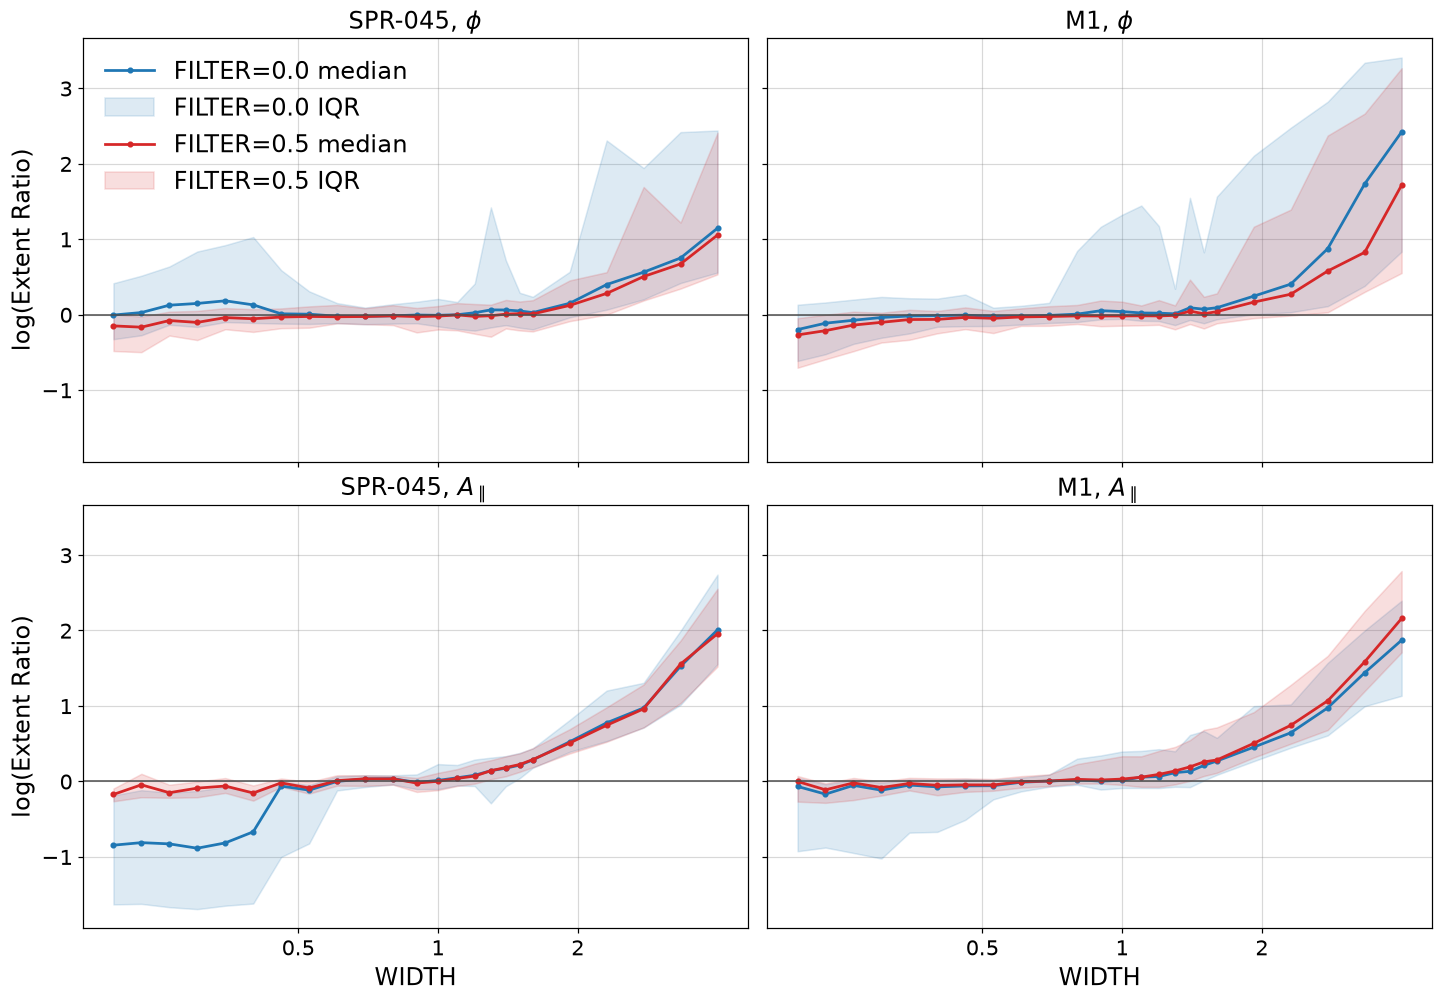

In [68]:
from matplotlib.ticker import StrMethodFormatter

fig12, axes12 = plt.subplots(len(fields), len(cases), figsize=(13, 9), sharex=True, sharey=True, squeeze=False)
field_labels = {"phi": r"$\phi$", "apar": r"$A_\parallel$", "bpar": r"$B_\parallel$"}

for row, f in enumerate(fields):
    for col, db in enumerate(cases):
        ax = axes12[row, col]
        for arm, colour in (("FILTER=0.0", "C0"), ("FILTER=0.5", "C3")):
            s = extent_bias[(extent_bias.db == db) & (extent_bias.arm == arm) & (extent_bias.field == f)]
            ax.plot(s.width, s["median"], color=colour, marker="o", ms=3, label=f"{arm} median")
            ax.fill_between(s.width, s.q25, s.q75, color=colour, alpha=0.15, label=f"{arm} IQR")
        ax.axhline(0, color="0.3", lw=1, marker="")
        ax.set_xscale("log")
        ax.set_title(f"{db}, {field_labels[f]}", fontsize=16)
        ax.tick_params(axis="both", labelsize=14)
    axes12[row, 0].set_ylabel("log(Extent Ratio)", fontsize=16)

for ax in axes12[-1]:
    ax.set_xlabel("WIDTH", fontsize=16)

axes12[0, 0].legend(fontsize=16)
ax = axes12[0, 0]
lims = ax.get_xlim()
ax.set_xticks([0.5, 1, 2, 5, 10])
ax.set_xlim(lims)
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:g}"))
ax.minorticks_off()
plt.show()

In [40]:
fig12.savefig(ROOT / "Plots" / analysis_name / "gftm_extent_ratio_vs_width_per_mode_filter.png")